# НИРМ 4 — метод с учётом пола: снижает ли он разрыв качества между мужчинами и женщинами

Анализ запусков `nirm4_sexaware_colab.ipynb` (Google Colab, Tesla T4): четыре варианта CNN-LSTM по 5 seed.

- `base` — CNN-LSTM недели 8 (контроль);
- `demo` — + возраст и пол на входе;
- `groupw` — веса примеров: равный вклад полов внутри каждого класса;
- `demo_groupw` — оба изменения.

**Критерий успеха (задан до просмотра результатов):** разрыв macro-AUC и чувствительности к MI
«женщины − мужчины» уменьшается, а общий macro-AUC не хуже базового больше чем на 0.005 (нижняя граница
95 % интервала разности > −0.005). Дополнительно — сочетание с порогами скрининга по полу (неделя 6).
Протокол оценки — недели 4; тестовый фолд 10 в выборе эпохи и порогов не участвует.

In [1]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata

SEED = 42
CACHE = 'cache' + os.sep
FIG_DIR = CACHE + 'fig' + os.sep
RESULTS = os.environ.get('NIRM4_RESULTS', CACHE + 'results_nirm4' + os.sep)
assert glob.glob(RESULTS + '*.json'), 'скачайте results_nirm4/ из Google Drive (см. ноутбук Colab)'
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
K_MI = SUPERCLASSES.index('MI')
VARIANTS = ['base', 'demo', 'groupw', 'demo_groupw']
LABELS = {'base': 'CNN-LSTM (week 8)', 'demo': '+ age, sex input', 'groupw': '+ sex-balanced loss',
          'demo_groupw': '+ both'}
COLORS = {'base': '#8C8C8C', 'demo': '#4C72B0', 'groupw': '#C98A1E', 'demo_groupw': '#6B4E9B'}

meta = np.load(CACHE + 'colab_meta_v2.npz')
Y, sex = meta['Y'].astype(int), meta['sex']

RUNS = {}
for f in sorted(glob.glob(RESULTS + '*.json')):
    info = json.load(open(f))
    z = np.load(f.replace('.json', '.npz'))
    RUNS[info['run_id']] = {**info, 's_val': z['s_val'], 's_test': z['s_test'], 'val_idx': z['val_idx'],
                            'test_idx': z['test_idx']}
first = next(iter(RUNS.values()))
va, te = first['val_idx'], first['test_idx']
assert all(np.array_equal(r['val_idx'], va) and np.array_equal(r['test_idx'], te) for r in RUNS.values())
y_va, y_te, sex_va, sex_te = Y[va], Y[te], sex[va], sex[te]
BY_VARIANT = {v: sorted((r for r in RUNS.values() if r['variant'] == v), key=lambda r: r['seed']) for v in VARIANTS}
print({v: [r['seed'] for r in rs] for v, rs in BY_VARIANT.items()}, '| среда:', first['env'])

ctrl = RUNS.get('cnnlstm_base_s42')
if ctrl and not first['smoke']:
    print(f"контроль: base seed 42 val macro-AUC {ctrl['val_macro_auc']:.4f} (неделя 8: 0.9363)")

{'base': [1, 2, 3, 4, 42], 'demo': [1, 2, 3, 4, 42], 'groupw': [1, 2, 3, 4, 42], 'demo_groupw': [1, 2, 3, 4, 42]} | среда: {'torch': '2.11.0+cu130', 'cuda': '13.0', 'device': 'cuda', 'gpu': 'Tesla T4'}
контроль: base seed 42 val macro-AUC 0.9363 (неделя 8: 0.9363)


## Протокол оценки (как на неделях 7–9)

In [2]:
N_BOOT = 1000
TARGET_SENS = 0.90


def auc_per_class(y, s):
    r = rankdata(s, axis=0)
    n_pos = y.sum(axis=0)
    n_neg = len(y) - n_pos
    return ((r * y).sum(axis=0) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def macro_auc(y, s):
    return auc_per_class(y, s).mean()


def screening_thresholds(y_val, s_val, target=TARGET_SENS):
    th = []
    for k in range(y_val.shape[1]):
        pos_scores = np.sort(s_val[y_val[:, k] == 1, k])
        th.append(pos_scores[int(np.floor((1 - target) * len(pos_scores)))])
    return np.array(th)


def tests(v):
    return [r['s_test'] for r in BY_VARIANT[v]]


def gap_vector(fi, mi, scores):
    """Разрыв «женщины − мужчины»: macro-AUC и AUC MI, усреднение по seed."""
    g = np.mean([auc_per_class(y_te[fi], s[fi]) - auc_per_class(y_te[mi], s[mi]) for s in scores], axis=0)
    return np.array([g.mean(), g[K_MI]])


F_IDX, M_IDX = np.where(sex_te == 'female')[0], np.where(sex_te == 'male')[0]
rng = np.random.default_rng(SEED)
BOOT_ALL = [rng.integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)]
BOOT_SEX = [(rng.choice(F_IDX, len(F_IDX)), rng.choice(M_IDX, len(M_IDX))) for _ in range(N_BOOT)]

## Задача 1. Общее качество и разрыв по полу

Все варианты оцениваются на одних и тех же бутстреп-выборках, поэтому разности с `base` — парные.

In [3]:
auc_boot = {v: np.array([np.mean([macro_auc(y_te[i], s[i]) for s in tests(v)]) for i in BOOT_ALL]) for v in VARIANTS}
gap_boot = {v: np.array([gap_vector(fi, mi, tests(v)) for fi, mi in BOOT_SEX]) for v in VARIANTS}

rows = []
for v in VARIANTS:
    auc = np.mean([macro_auc(y_te, s) for s in tests(v)])
    gap = gap_vector(F_IDX, M_IDX, tests(v))
    d_auc = auc_boot[v] - auc_boot['base']
    d_gap = gap_boot[v] - gap_boot['base']
    per_seed = [macro_auc(y_te, s) for s in tests(v)]
    rows.append({
        'variant': v, 'seeds': len(per_seed), 'val macro-AUC': np.mean([r['val_macro_auc'] for r in BY_VARIANT[v]]),
        'test macro-AUC': auc, 'AUC CI low': np.percentile(auc_boot[v], 2.5),
        'AUC CI high': np.percentile(auc_boot[v], 97.5), 'sd over seeds': np.std(per_seed, ddof=1),
        'Δ AUC vs base': auc - np.mean([macro_auc(y_te, s) for s in tests('base')]),
        'Δ AUC low': np.percentile(d_auc, 2.5), 'Δ AUC high': np.percentile(d_auc, 97.5),
        'gap macro': gap[0], 'gap macro low': np.percentile(gap_boot[v][:, 0], 2.5),
        'gap macro high': np.percentile(gap_boot[v][:, 0], 97.5),
        'gap MI': gap[1], 'gap MI low': np.percentile(gap_boot[v][:, 1], 2.5),
        'gap MI high': np.percentile(gap_boot[v][:, 1], 97.5),
        'Δ gap macro vs base low': np.percentile(d_gap[:, 0], 2.5),
        'Δ gap macro vs base high': np.percentile(d_gap[:, 0], 97.5),
        'Δ gap MI vs base low': np.percentile(d_gap[:, 1], 2.5),
        'Δ gap MI vs base high': np.percentile(d_gap[:, 1], 97.5),
        'non-inferior (Δ low > -0.005)': np.percentile(d_auc, 2.5) > -0.005})
summary = pd.DataFrame(rows).set_index('variant')
print(summary.T.round(4).to_string())

per_sex = pd.DataFrame({v: {'female macro-AUC': np.mean([macro_auc(y_te[F_IDX], s[F_IDX]) for s in tests(v)]),
                            'male macro-AUC': np.mean([macro_auc(y_te[M_IDX], s[M_IDX]) for s in tests(v)]),
                            'female MI AUC': np.mean([auc_per_class(y_te[F_IDX], s[F_IDX])[K_MI] for s in tests(v)]),
                            'male MI AUC': np.mean([auc_per_class(y_te[M_IDX], s[M_IDX])[K_MI] for s in tests(v)])}
                        for v in VARIANTS}).T
print('\nкачество по полу (среднее по seed):')
print(per_sex.round(4).to_string())

variant                            base      demo    groupw demo_groupw
seeds                                 5         5         5           5
val macro-AUC                  0.936241  0.936557  0.936364     0.93609
test macro-AUC                 0.932271  0.933693   0.93215    0.932958
AUC CI low                     0.925632  0.927107  0.925227    0.926315
AUC CI high                    0.938158  0.939579  0.938141    0.938738
sd over seeds                  0.000842  0.000487   0.00196    0.000994
Δ AUC vs base                       0.0  0.001422 -0.000121    0.000687
Δ AUC low                           0.0  0.000548 -0.001107   -0.000361
Δ AUC high                          0.0  0.002328   0.00083    0.001744
gap macro                     -0.019017 -0.020053 -0.017757   -0.018528
gap macro low                 -0.032321 -0.033048 -0.030821    -0.03133
gap macro high                -0.006635 -0.007176 -0.005035   -0.005651
gap MI                        -0.023675 -0.024445   -0.0242   -0

## Задача 2. Чувствительность к MI при скрининге

Две политики порога, подобранного на фолде 9 (чувствительность ≥ 0.90): общий для всех и отдельный для
каждого пола (неделя 6). Для каждого seed порог свой, затем среднее по seed.

In [4]:
def screening(v, policy):
    out = {'female sens': [], 'male sens': [], 'female spec': [], 'male spec': []}
    for r in BY_VARIANT[v]:
        common = screening_thresholds(y_va, r['s_val'])
        for g in ('female', 'male'):
            th = common if policy == 'common' else screening_thresholds(y_va[sex_va == g], r['s_val'][sex_va == g])
            m = sex_te == g
            pred = r['s_test'][m, K_MI] >= th[K_MI]
            yk = y_te[m, K_MI]
            out[f'{g} sens'].append(pred[yk == 1].mean())
            out[f'{g} spec'].append(1 - pred[yk == 0].mean())
    res = {k: np.mean(vals) for k, vals in out.items()}
    res['sens gap'] = res['female sens'] - res['male sens']
    return res


sens = pd.DataFrame([{'variant': v, 'policy': p, **screening(v, p)} for v in VARIANTS for p in ('common', 'by sex')])
print(sens.set_index(['variant', 'policy']).round(3).to_string())

                    female sens  male sens  female spec  male spec  sens gap
variant     policy                                                          
base        common        0.891      0.919        0.796      0.800    -0.028
            by sex        0.911      0.904        0.756      0.824     0.007
demo        common        0.884      0.929        0.804      0.808    -0.045
            by sex        0.914      0.913        0.753      0.832     0.001
groupw      common        0.898      0.916        0.776      0.814    -0.018
            by sex        0.907      0.908        0.754      0.823    -0.001
demo_groupw common        0.899      0.915        0.764      0.818    -0.016
            by sex        0.904      0.914        0.756      0.820    -0.010


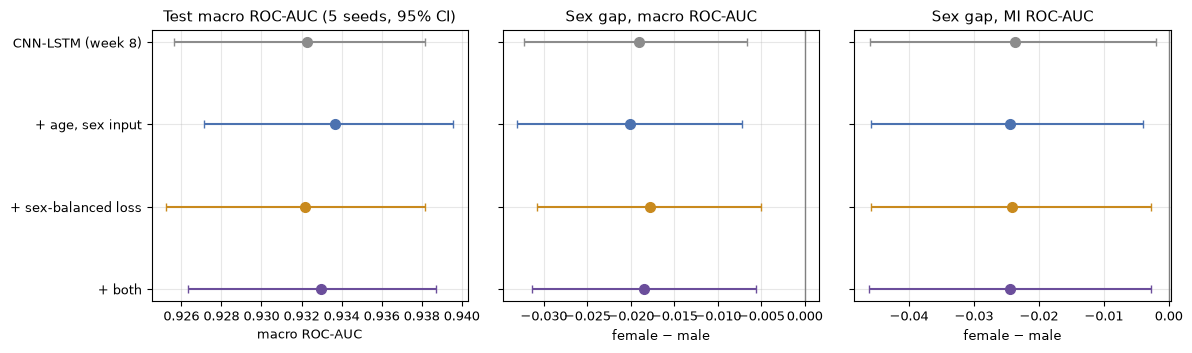

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
yy = np.arange(len(VARIANTS))[::-1]
for y_, v in zip(yy, VARIANTS):
    s = summary.loc[v]
    ax[0].errorbar(s['test macro-AUC'], y_, xerr=[[s['test macro-AUC'] - s['AUC CI low']],
                                                   [s['AUC CI high'] - s['test macro-AUC']]],
                   fmt='o', ms=7, capsize=3, color=COLORS[v])
    for a, col in ((ax[1], 'gap macro'), (ax[2], 'gap MI')):
        a.errorbar(s[col], y_, xerr=[[s[col] - s[f'{col} low']], [s[f'{col} high'] - s[col]]],
                   fmt='o', ms=7, capsize=3, color=COLORS[v])
ax[0].set_yticks(yy, [LABELS[v] for v in VARIANTS])
ax[0].set(title='Test macro ROC-AUC (5 seeds, 95% CI)', xlabel='macro ROC-AUC')
for a, title in ((ax[1], 'Sex gap, macro ROC-AUC'), (ax[2], 'Sex gap, MI ROC-AUC')):
    a.axvline(0, color='gray', lw=1)
    a.set_yticks(yy, [''] * len(yy))
    a.set(title=title, xlabel='female − male')
plt.tight_layout()
plt.savefig(FIG_DIR + 'n4_gap.png', dpi=150)
plt.show()

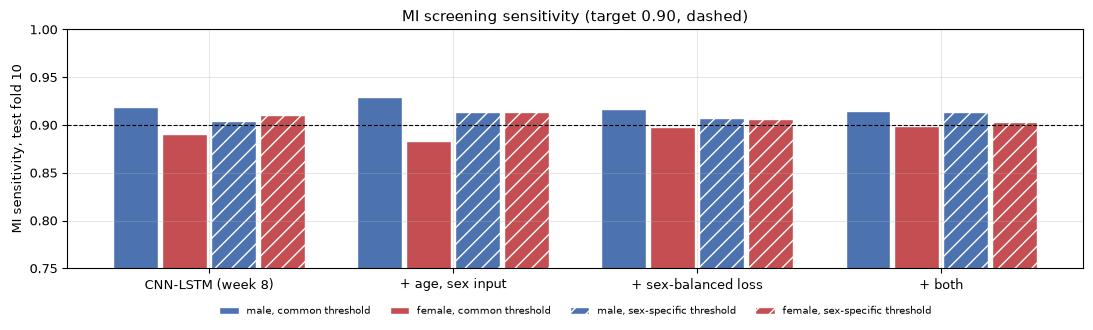

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.4))
x = np.arange(len(VARIANTS))
w = 0.2
for j, (policy, hatch) in enumerate((('common', ''), ('by sex', '//'))):
    for k, (g, color) in enumerate((('male', '#4C72B0'), ('female', '#C44E52'))):
        vals = sens[sens.policy == policy].set_index('variant').loc[VARIANTS, f'{g} sens']
        ax.bar(x + (2 * j + k - 1.5) * w, vals, w * 0.92, color=color, hatch=hatch, edgecolor='white',
               label=f'{g}, {"common" if policy == "common" else "sex-specific"} threshold')
ax.axhline(TARGET_SENS, color='black', ls='--', lw=0.8)
ax.set_xticks(x, [LABELS[v] for v in VARIANTS])
ax.set(ylim=(0.75, 1.0), ylabel='MI sensitivity, test fold 10', title='MI screening sensitivity (target 0.90, dashed)')
ax.legend(fontsize=7, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR + 'n4_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
json.dump({'summary': summary.reset_index().to_dict('records'), 'per_sex': per_sex.reset_index().to_dict('records'),
           'screening': sens.to_dict('records')}, open(CACHE + 'n4_summary.json', 'w'), indent=1, default=float)
print('сохранено: n4_summary.json, n4_gap.png, n4_sensitivity.png')

сохранено: n4_summary.json, n4_gap.png, n4_sensitivity.png


## Выводы

**Контроль воспроизведён.** `base` с seed 42 дал val macro-AUC 0.9363 и лучшую эпоху 15 — бит в бит как CNN-LSTM
недели 8; варианты обучены тем же кодом в одной сессии.

**Общее качество не пострадало ни в одном варианте.** Все варианты не хуже базового (нижняя граница разности
> −0.005). Возраст и пол на входе дают небольшой, но значимый прирост: +0.0014 [+0.0005; +0.0023] macro-AUC
(0.9337 против 0.9323), и уменьшают разброс по seed (0.0005 против 0.0008).

**Критерий успеха не выполнен: разрыв по полу в различающей способности не сократился.** Разрыв macro-AUC
«женщины − мужчины»: base −0.019, + возраст и пол −0.020, + веса по полу −0.018, оба −0.019; по MI во всех
вариантах −0.024. Интервалы разностей с базовым вариантом включают 0. Возраст и пол улучшают распознавание у
обоих полов почти одинаково (у женщин +0.001, у мужчин +0.002), а уравновешивание вклада полов в функции
потерь качество у женщин не повышает.

**Что это значит.** Отвергнуты два самых распространённых объяснения разрыва: (1) модели не хватает
демографического контекста и (2) женщин мало в обучении, поэтому их вклад в обучение мал. Разрыв сохраняется и
при одинаковом вкладе полов — значит, женские ЭКГ в PTB-XL распознавать по существу труднее (объяснения модели
недели 9 указывают на отведения V4–V5 и комплекс QRS), а не модель «недоучена» на женщинах.

**Скрининг: порог по полу выравнивает чувствительность, но разрыв переходит в специфичность.** При общем пороге
чувствительность к MI у женщин 0.891 против 0.919 у мужчин; веса по полу немного сокращают разрыв (−0.028 → −0.018)
ценой специфичности у женщин (0.796 → 0.776). Пороги по полу выравнивают чувствительность у всех вариантов
(разрыв от −0.010 до +0.007), но специфичность у женщин тогда ниже: 0.756 против 0.824 у мужчин у базовой модели.
Это честная форма компромисса: при равной вероятности не пропустить инфаркт у женщин больше ложных тревог.
(Для порогов приведены точечные оценки по 5 seed, без интервалов.)

**Следствие для новизны.** Метод «модель + клинические признаки + веса по полу» как способ устранить разрыв —
не подтверждён. Подтверждены: (1) разрыв устойчив и не объясняется ни архитектурой, ни балансом обучения, ни
составом подтипов, ни помехами; (2) объяснения модели различаются по полу; (3) пороги по полу обеспечивают
одинаковую чувствительность скрининга при явной цене в специфичности; (4) возраст и пол на входе немного
повышают общее качество. Следующая проверяемая гипотеза — различие амплитуды женских ЭКГ (неделя 3: медиана
максимального размаха 2.34 против 2.80 мВ) и вклад отведений V4–V5: нормировка с учётом пола или обучение на
отведениях с поправкой на амплитуду.